\# 01 - Vanilla GAN on Fashion
**Framework:** PyTorch

> **Dataset reliability:** this notebook uses the official local cache when available. If the download is blocked, the session pack automatically switches to its bundled offline fallback without crashing.

## Learning objectives
- Build G and D from scratch.
- Understand `detach()`, `zero_grad()`, and alternating updates.
- Visualize learning with fixed latent vectors.

In [1]:
import os, math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()

device: cuda


In [2]:
# Colab-ready, self-contained dataset loader.
# Order: local torchvision cache -> online download -> built-in offline fallback.
import os
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

_DATA_ROOT = Path('/content/gan_data') if Path('/content').exists() else Path.cwd() / 'gan_data'
_DATA_ROOT.mkdir(parents=True, exist_ok=True)


def _offline_digits_dataset():
    """MNIST-like fallback generated from sklearn's built-in digits dataset."""
    try:
        from sklearn.datasets import load_digits
        import torch.nn.functional as F
        d = load_digits()
        x = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
        x = F.interpolate(x, size=(28, 28), mode='bilinear', align_corners=False)
        x = x * 2 - 1
        y = torch.tensor(d.target, dtype=torch.long)
        # Repeat a few times so GAN training has enough mini-batches.
        x = x.repeat((4, 1, 1, 1))
        y = y.repeat(4)
        return TensorDataset(x, y), 'offline sklearn digits fallback'
    except Exception as exc:
        raise RuntimeError('Offline MNIST fallback failed. In Colab, install scikit-learn with: !pip -q install scikit-learn') from exc


def _synthetic_fashion_dataset(n=4000, seed=42):
    """Small deterministic fashion-like fallback; used only if FashionMNIST cannot be downloaded."""
    rng = np.random.default_rng(seed)
    images = np.zeros((n, 28, 28), dtype=np.float32)
    labels = np.arange(n, dtype=np.int64) % 10

    def add_rect(img, x0, y0, x1, y1, v=1.0):
        img[max(0,y0):min(28,y1), max(0,x0):min(28,x1)] = np.maximum(img[max(0,y0):min(28,y1), max(0,x0):min(28,x1)], v)

    for i, cls in enumerate(labels):
        img = np.zeros((28,28), dtype=np.float32)
        # jitter so classes are not identical copies
        dx, dy = rng.integers(-2,3), rng.integers(-2,3)
        if cls == 0:  # T-shirt
            add_rect(img, 8+dx, 8+dy, 20+dx, 22+dy); add_rect(img, 4+dx, 9+dy, 8+dx, 15+dy); add_rect(img, 20+dx, 9+dy, 24+dx, 15+dy)
        elif cls == 1:  # Trouser
            add_rect(img, 9+dx, 5+dy, 19+dx, 13+dy); add_rect(img, 9+dx, 13+dy, 13+dx, 25+dy); add_rect(img, 15+dx, 13+dy, 19+dx, 25+dy)
        elif cls == 2:  # Pullover
            add_rect(img, 8+dx, 7+dy, 20+dx, 23+dy); add_rect(img, 4+dx, 8+dy, 8+dx, 20+dy); add_rect(img, 20+dx, 8+dy, 24+dx, 20+dy)
        elif cls == 3:  # Dress
            add_rect(img, 10+dx, 5+dy, 18+dx, 13+dy)
            for y in range(13+dy, 24+dy):
                w = 4 + max(0, y-(13+dy))//2
                add_rect(img, 14-w+dx, y, 14+w+dx, y+1)
        elif cls == 4:  # Coat
            add_rect(img, 8+dx, 5+dy, 20+dx, 25+dy); add_rect(img, 4+dx, 7+dy, 8+dx, 22+dy); add_rect(img, 20+dx, 7+dy, 24+dx, 22+dy)
        elif cls == 5:  # Sandal
            add_rect(img, 5+dx, 19+dy, 24+dx, 23+dy); add_rect(img, 8+dx, 14+dy, 20+dx, 17+dy); add_rect(img, 17+dx, 10+dy, 20+dx, 19+dy)
        elif cls == 6:  # Shirt
            add_rect(img, 8+dx, 7+dy, 20+dx, 23+dy); add_rect(img, 5+dx, 9+dy, 8+dx, 15+dy); add_rect(img, 20+dx, 9+dy, 23+dx, 15+dy); add_rect(img, 12+dx, 5+dy, 16+dx, 8+dy)
        elif cls == 7:  # Sneaker
            add_rect(img, 5+dx, 18+dy, 24+dx, 23+dy); add_rect(img, 11+dx, 13+dy, 20+dx, 19+dy); add_rect(img, 18+dx, 11+dy, 22+dx, 19+dy)
        elif cls == 8:  # Bag
            add_rect(img, 7+dx, 10+dy, 21+dx, 24+dy)
            # handle
            for a in range(-5,6):
                x = 14+a+dx; y = int(10 - np.sqrt(max(0,25-a*a))/2)+dy
                if 0 <= x < 28 and 0 <= y < 28: img[y:y+2, x] = 1.0
        else:  # Ankle boot
            add_rect(img, 7+dx, 11+dy, 16+dx, 23+dy); add_rect(img, 7+dx, 20+dy, 23+dx, 24+dy); add_rect(img, 14+dx, 17+dy, 21+dx, 22+dy)
        # soften + add tiny noise
        img = np.clip(img + rng.normal(0, 0.06, img.shape), 0, 1)
        images[i] = img

    x = torch.tensor(images, dtype=torch.float32).unsqueeze(1) * 2 - 1
    y = torch.tensor(labels, dtype=torch.long)
    return TensorDataset(x, y), 'offline synthetic fashion-like fallback'


def load_mnist_like(batch_size=128, fashion=True):
    dataset_name = 'FashionMNIST' if fashion else 'MNIST'
    force_offline = os.environ.get('GAN_DATA_MODE', '').strip().lower() in {'offline','local','fallback'}
    ds = None
    source = None

    if not force_offline:
        try:
            from torchvision import datasets, transforms
            ds_cls = datasets.FashionMNIST if fashion else datasets.MNIST
            transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.5,), (0.5,)),
            ])
            # First try cached data, then allow download. This is the normal Colab path.
            try:
                ds = ds_cls(str(_DATA_ROOT), train=True, download=False, transform=transform)
                source = f'cached official {dataset_name}'
            except Exception:
                ds = ds_cls(str(_DATA_ROOT), train=True, download=True, transform=transform)
                source = f'downloaded official {dataset_name}'
        except Exception as exc:
            print(f'Official {dataset_name} unavailable: {type(exc).__name__}: {exc}')

    if ds is None:
        if fashion:
            ds, source = _synthetic_fashion_dataset()
        else:
            ds, source = _offline_digits_dataset()
        print(f'Using {source}. This keeps the notebook runnable even without network access.')

    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, drop_last=True)
    print(f'Dataset source: {source} | samples: {len(ds)} | batches: {len(loader)}')
    return loader, 28, 10


In [3]:
loader, image_size, num_classes = load_mnist_like(batch_size=128, fashion=True)
len(loader), image_size

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.86MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.9MB/s]


Dataset source: downloaded official FashionMNIST | samples: 60000 | batches: 468


(468, 28)

## 1. Generator and Discriminator
We use simple MLPs so the training logic stays visible.

In [11]:
latent_dim=300
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(latent_dim,256),nn.LeakyReLU(0.2),nn.Linear(256,512),nn.LeakyReLU(0.2),nn.Linear(512,28*28),nn.Tanh())
    def forward(self,z): return self.net(z).view(-1,1,28,28)
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(28*28,512),nn.LeakyReLU(0.2),nn.Linear(512,256),nn.LeakyReLU(0.2),nn.Linear(256,1))
    def forward(self,x): return self.net(x)
G,D=Generator().to(device),Discriminator().to(device)
criterion=nn.BCEWithLogitsLoss()
g_opt=torch.optim.Adam(G.parameters(),lr=2e-4,betas=(0.5,0.999))
d_opt=torch.optim.Adam(D.parameters(),lr=2e-4,betas=(0.5,0.999))

In [12]:
@torch.no_grad()
def show_samples(G, z_fixed, nrow=8, title='Generated samples'):
    G.eval(); x=G(z_fixed).cpu()
    x=(x.clamp(-1,1)+1)/2
    n=min(len(x), nrow*nrow)
    fig, axes=plt.subplots(math.ceil(n/nrow), nrow, figsize=(10,10))
    axes=np.array(axes).reshape(-1)
    for i,ax in enumerate(axes):
        ax.axis('off')
        if i<n: ax.imshow(x[i,0], cmap='gray')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    G.train()

## 2. Training loop
Study the two phases carefully. The Discriminator phase uses `fake.detach()`; the Generator phase does not.

epoch 01 | D 0.827 | G 1.754


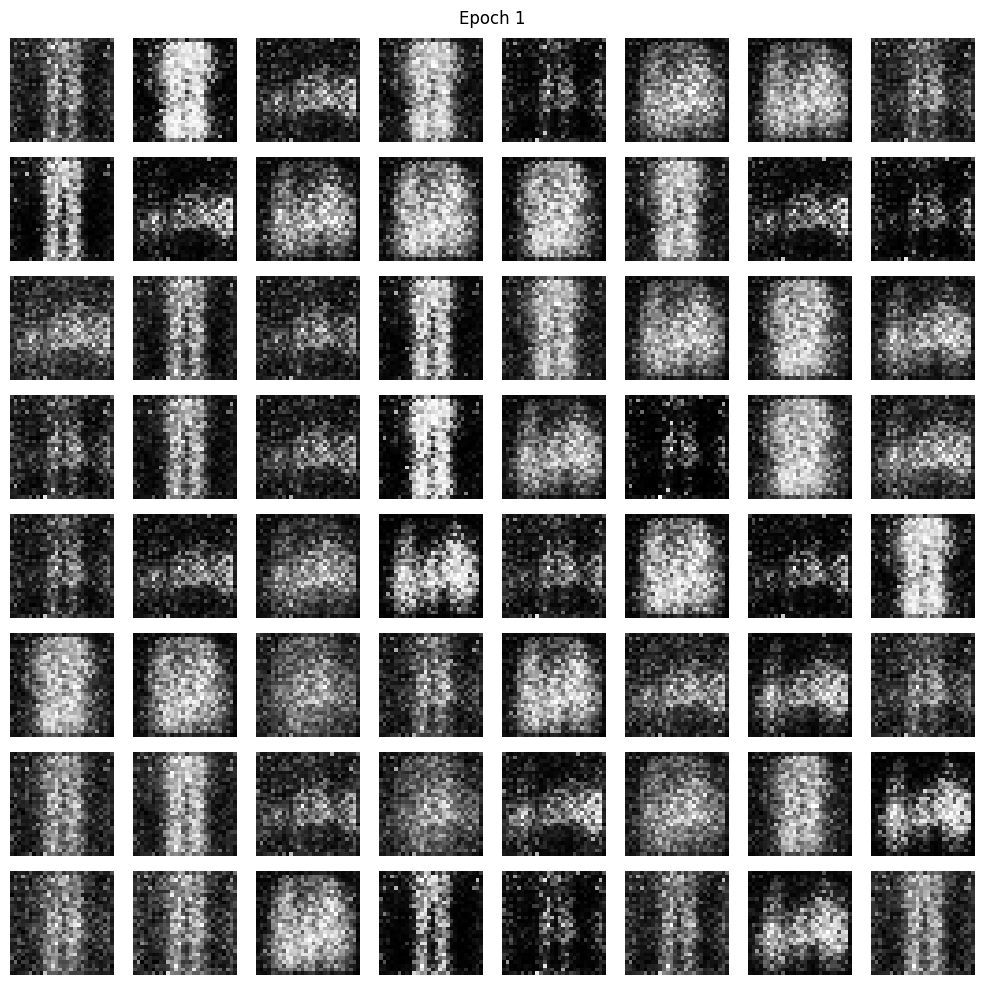

epoch 02 | D 0.843 | G 2.206


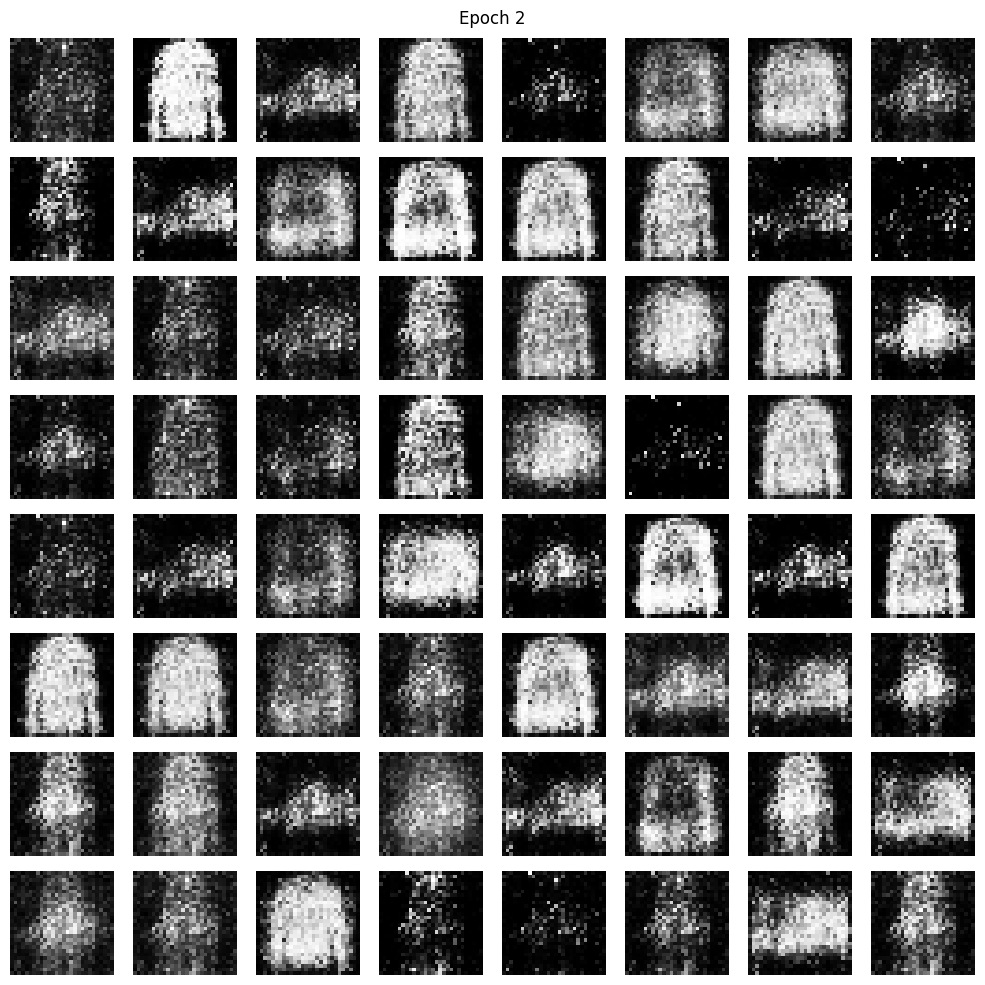

epoch 03 | D 0.846 | G 2.147


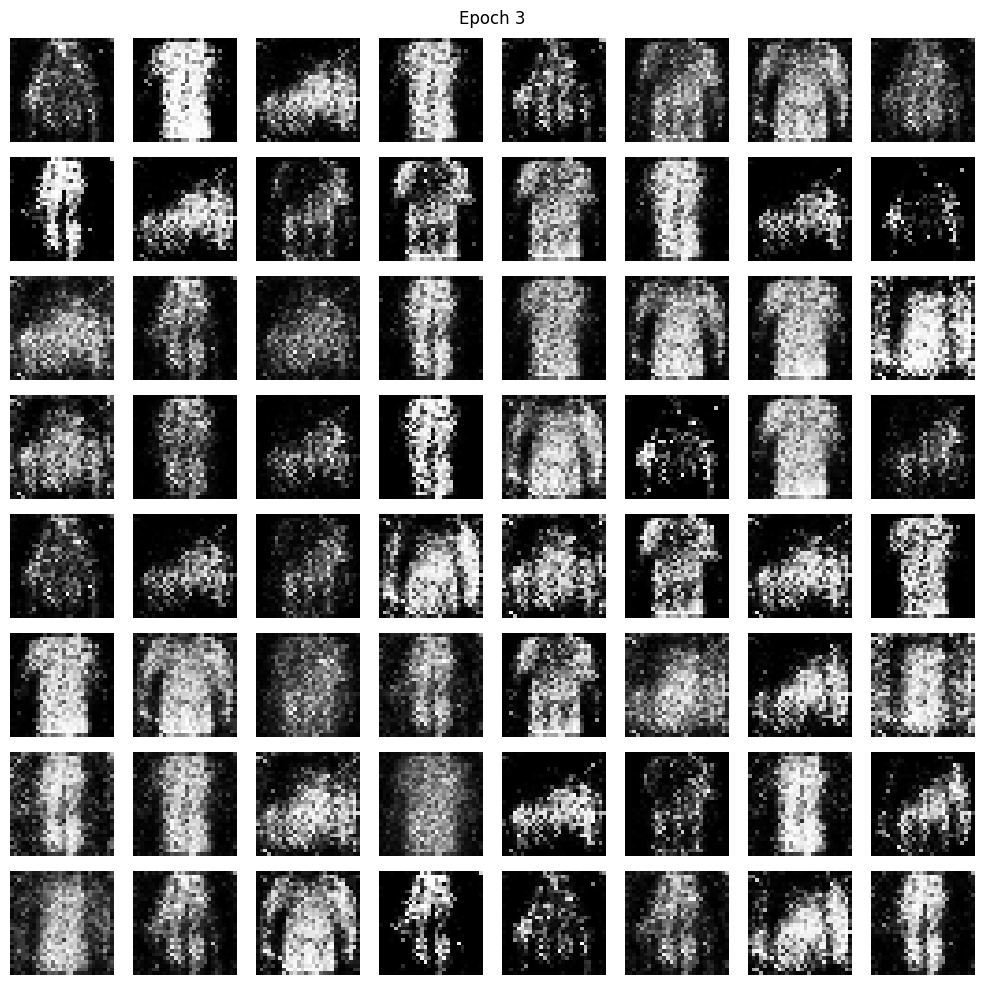

epoch 04 | D 0.912 | G 1.977


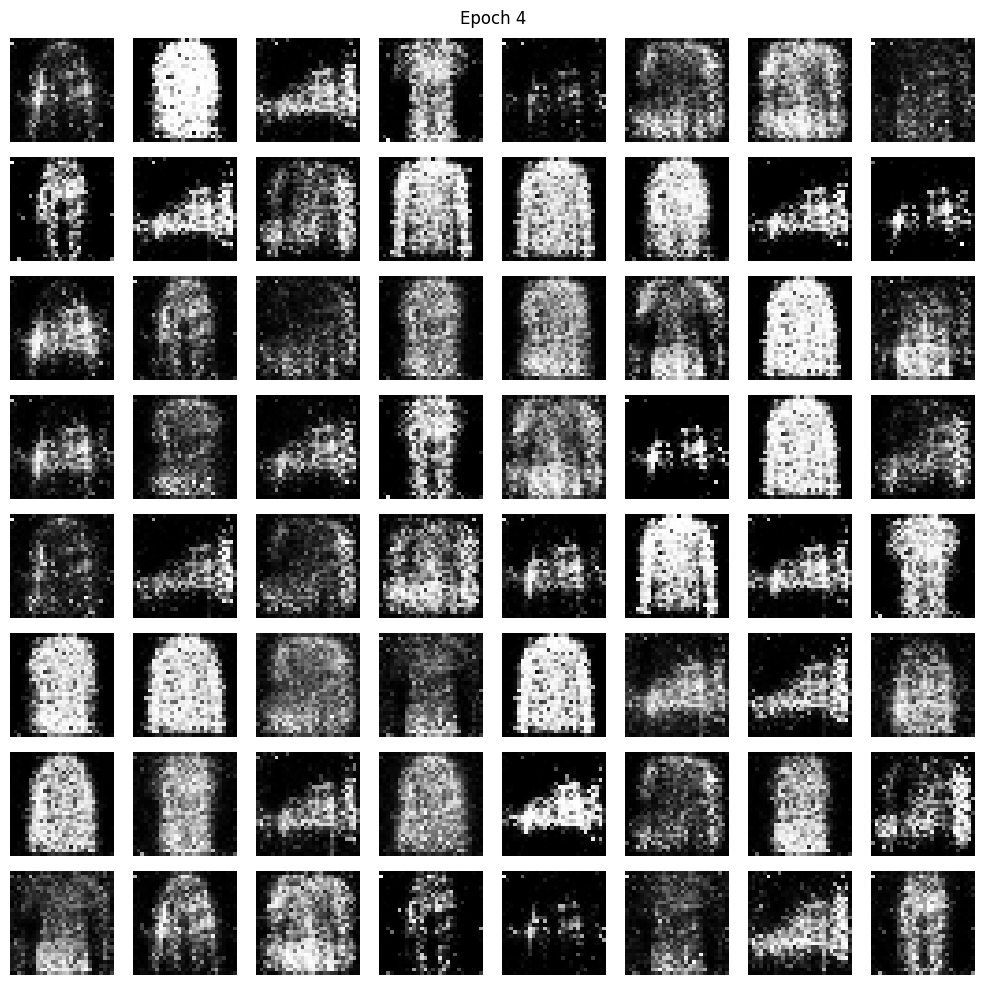

epoch 05 | D 0.955 | G 1.838


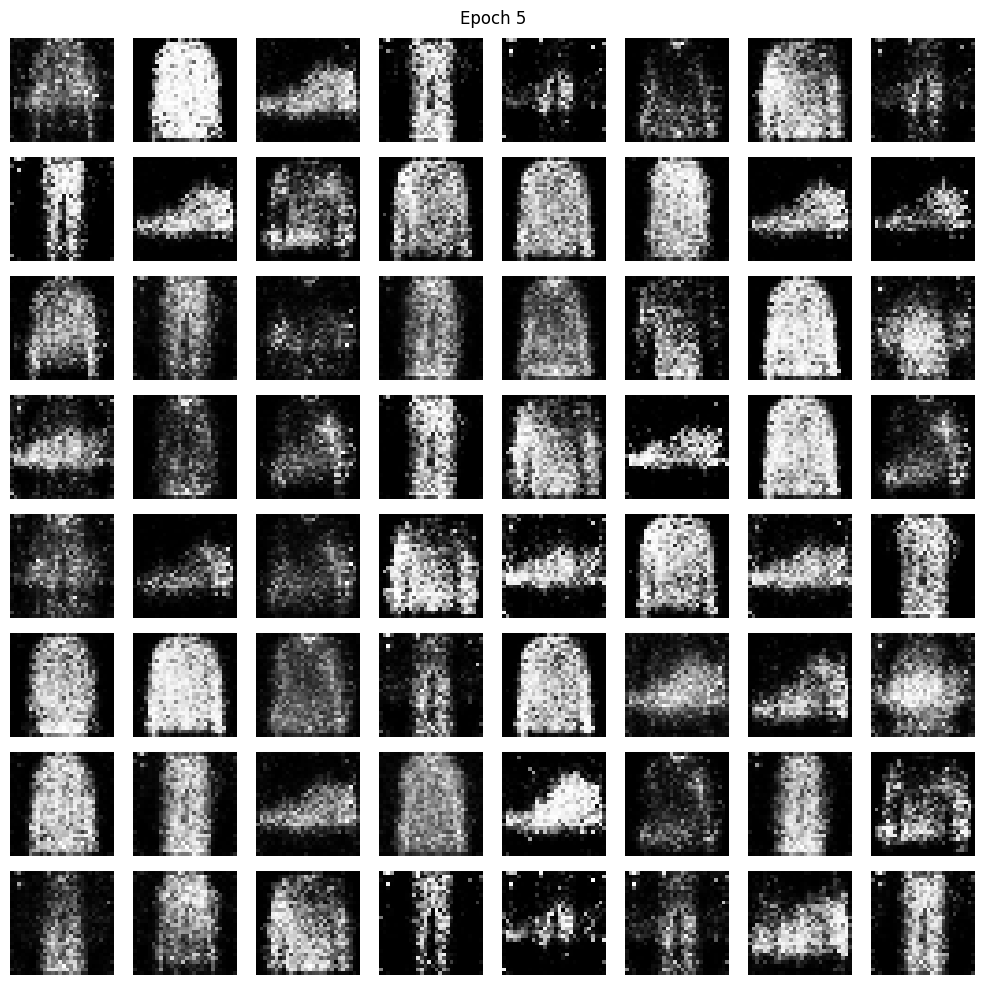

In [13]:
epochs=5  # use 20-50 after class / on GPU
z_fixed=torch.randn(64,latent_dim,device=device)
history={'g':[],'d':[]}
for epoch in range(1,epochs+1):
    for real,_ in loader:
        real=real.to(device); b=real.size(0)
        real_y=torch.full((b,1),0.9,device=device); fake_y=torch.zeros(b,1,device=device)
        # ---- D step ----
        d_opt.zero_grad()
        z=torch.randn(b,latent_dim,device=device)
        fake=G(z)
        d_loss=criterion(D(real),real_y)+criterion(D(fake.detach()),fake_y)
        d_loss.backward(); d_opt.step()
        # ---- G step ----
        g_opt.zero_grad()
        pred=D(fake)
        g_loss=criterion(pred,real_y)
        g_loss.backward(); g_opt.step()
        history['d'].append(d_loss.item()); history['g'].append(g_loss.item())
    print(f'epoch {epoch:02d} | D {np.mean(history["d"][-len(loader):]):.3f} | G {np.mean(history["g"][-len(loader):]):.3f}')
    show_samples(G,z_fixed,title=f'Epoch {epoch}')

## 3. Student tasks
1. Remove `detach()` and explain what gradients are created.
2. Change `latent_dim` from 100 to 32. What changes?
3. Use one-sided label smoothing: real target = 0.9. Compare stability.
4. Save the same `z_fixed` grid at epochs 1, 5, 10, 20.

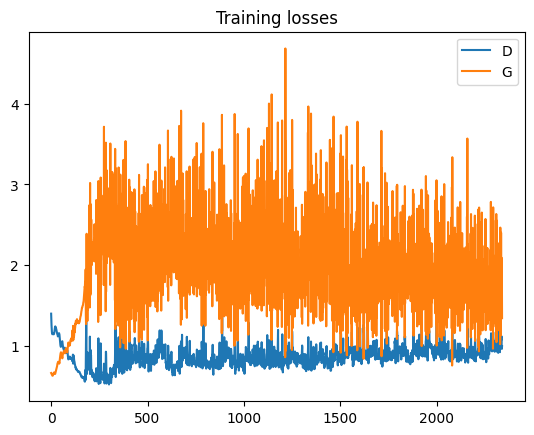

In [14]:
plt.plot(history['d'],label='D'); plt.plot(history['g'],label='G'); plt.legend(); plt.title('Training losses'); plt.show()